# Projet final : les récoltes agricoles

**Équipe :** (nom de l'équipe et des 5 membres)

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

On regarde d'abord la taille du fichier et le type de chaque colonne.

In [2]:
print("Lignes, colonnes :", brut.shape)
brut.dtypes

Lignes, colonnes : (408, 6)


annee           int64
saison            str
departement       str
culture           str
surface_ha        str
production_t      str
dtype: object

`surface_ha` et `production_t` devraient être des nombres, or pandas les lit comme du texte (`str`) : certaines cellules contiennent donc autre chose que des chiffres. On cherche lesquelles.

In [3]:
for colonne in ["surface_ha", "production_t"]:
    valeurs = brut[colonne].dropna()
    pas_nombre = valeurs[pd.to_numeric(valeurs, errors="coerce").isna()]
    print(f"{colonne} : {len(pas_nombre)} valeurs qui ne sont pas des nombres, par exemple {list(pas_nombre.unique()[:6])}")

surface_ha : 22 valeurs qui ne sont pas des nombres, par exemple ['2 517', '541 ha', '1 127', '1 185', '1 748', '492 ha']
production_t : 50 valeurs qui ne sont pas des nombres, par exemple ['3753 t', '2299 t', '1306 t', '2394 t', '599 t', '767 t']


Valeurs manquantes et lignes en double :

In [4]:
print("Valeurs manquantes par colonne :")
print(brut.isna().sum())
print()
print("Lignes en double :", brut.duplicated().sum())

Valeurs manquantes par colonne :
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64

Lignes en double : 18


Toutes les écritures de chaque colonne de texte. Il devrait y avoir 2 saisons, 10 départements et 7 cultures.

In [5]:
for colonne in ["saison", "departement", "culture"]:
    ecritures = brut[colonne].unique()
    print(f"{colonne} : {len(ecritures)} écritures différentes")
    print(sorted(ecritures, key=str.lower))
    print()

saison : 2 écritures différentes
['Automne', 'Printemps']

departement : 44 écritures différentes
[' Artibonite', ' Centre', " Grand'Anse", ' Nord', ' Nord-Est', ' Nord-Ouest', ' Ouest', ' Sud', ' Sud-Est', 'Artibonite', 'ARTIBONITE', 'artibonite', 'Centre', 'centre', "Grand'Anse", "grand'anse", "GRAND'ANSE", "Grand'Anse ", 'Nippes', 'NIPPES', 'Nippes ', 'Nord', 'NORD', 'nord', 'Nord ', 'Nord-Est', 'nord-est', 'NORD-EST', 'Nord-Est ', 'NORD-OUEST', 'Nord-Ouest', 'nord-ouest', 'Nord-Ouest ', 'Ouest', 'ouest', 'OUEST', 'Ouest ', 'Sud', 'SUD', 'sud', 'Sud ', 'Sud-Est', 'sud-est', 'Sud-Est ']

culture : 33 écritures différentes
[' Banane', ' Haricot', ' Igname', ' Maïs', ' Pois congo', ' Riz', ' Sorgho', 'banane', 'Banane', 'BANANE', 'Banane ', 'Haricot', 'HARICOT', 'haricot', 'Haricot ', 'Igname', 'IGNAME', 'igname', 'Igname ', 'maïs', 'Maïs', 'MAÏS', 'Maïs ', 'Pois congo', 'POIS CONGO', 'pois congo', 'Pois congo ', 'Riz', 'Riz ', 'Sorgho', 'SORGHO', 'sorgho', 'Sorgho ']



In [6]:
print("Années :", sorted(brut["annee"].unique()))

Années : [np.int64(2023), np.int64(2024), np.int64(2025)]


**Problèmes trouvés**, à corriger à l'étape 2 :

1. **Nombres écrits comme du texte** : 22 surfaces et 50 productions contiennent une unité (`"541 ha"`, `"3753 t"`) ou un espace entre les milliers (`"2 517"`).
2. **Écritures multiples** : 44 écritures pour 10 départements et 33 pour 7 cultures, à cause d'espaces avant ou après (`" Maïs"`, `"Ouest "`) et de majuscules (`"NORD-OUEST"`, `"pois congo"`).
3. **Valeurs manquantes** : 15 productions sont vides.
4. **Doublons** : 18 lignes sont répétées à l'identique.

Les colonnes `annee` (3 valeurs) et `saison` (2 valeurs) sont déjà propres.

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [7]:
propre = brut.copy()
print("Lignes au départ :", len(propre))

Lignes au départ : 408


**Problème 1 : les nombres écrits comme du texte.** On retire l'unité et les espaces, puis on convertit en nombre. La production reste décimale (`float`) tant qu'il y a des valeurs manquantes.

In [8]:
for colonne in ["surface_ha", "production_t"]:
    propre[colonne] = (
        propre[colonne]
        .str.replace(" ha", "")
        .str.replace(" t", "")
        .str.replace(" ", "")
    )
    propre[colonne] = pd.to_numeric(propre[colonne])

propre[["surface_ha", "production_t"]].describe()

,surface_ha,production_t
count,408.000000,393.000000
mean,1213.852941,3494.437659
std,864.128299,4516.396156
min,150.000000,103.000000
25%,573.750000,639.000000
50%,1017.500000,1489.000000
75%,1587.500000,4815.000000
max,4065.000000,24133.000000


Aucune erreur de conversion, et pas de valeur négative ni nulle : les minimums sont positifs.

**Problème 2 : les écritures multiples.** On enlève les espaces, on passe en minuscules, puis on remplace chaque nom par son écriture officielle, celle des fichiers `departements.csv` et `cultures.csv`. `.str.capitalize()` ne suffirait pas : il donnerait `"Nord-ouest"` et `"Grand'anse"`.

In [9]:
noms_departements = pd.read_csv("donnees/departements.csv")["departement"]
noms_cultures = pd.read_csv("donnees/cultures.csv")["culture"]

officiel_departement = {nom.lower(): nom for nom in noms_departements}
officiel_culture = {nom.lower(): nom for nom in noms_cultures}

propre["saison"] = propre["saison"].str.strip()
propre["departement"] = propre["departement"].str.strip().str.lower().map(officiel_departement)
propre["culture"] = propre["culture"].str.strip().str.lower().map(officiel_culture)

# Un nom inconnu deviendrait une valeur manquante : on vérifie qu'il n'y en a aucun.
print("Noms non reconnus :", propre["departement"].isna().sum() + propre["culture"].isna().sum())
print(propre["departement"].unique())
print(propre["culture"].unique())

Noms non reconnus : 0
<ArrowStringArray>
[     'Ouest', 'Artibonite',       'Nord',        'Sud',     'Centre',
 'Nord-Ouest',    'Sud-Est', 'Grand'Anse',   'Nord-Est',     'Nippes']
Length: 10, dtype: str
<ArrowStringArray>
['Maïs', 'Sorgho', 'Riz', 'Haricot', 'Pois congo', 'Banane', 'Igname']
Length: 7, dtype: str


**Problème 3 : les doublons.** On les supprime *après* avoir uniformisé les noms : `"Ouest"` et `"Ouest "` ne sont reconnus comme identiques qu'une fois les espaces retirés. Garder un doublon compterait deux fois la même récolte.

In [10]:
avant = len(propre)
propre = propre.drop_duplicates()
print(f"Doublons supprimés : {avant - len(propre)} ({avant} -> {len(propre)} lignes)")

Doublons supprimés : 18 (408 -> 390 lignes)


**Problème 4 : les productions manquantes.** Sans production, on ne peut calculer ni rendement ni valeur. Remplacer le vide par une moyenne inventerait une récolte : on supprime ces lignes.

In [11]:
avant = len(propre)
propre = propre.dropna(subset=["production_t"])
propre["production_t"] = propre["production_t"].astype(int)
propre = propre.reset_index(drop=True)
print(f"Lignes sans production supprimées : {avant - len(propre)} ({avant} -> {len(propre)} lignes)")

Lignes sans production supprimées : 14 (390 -> 376 lignes)


**Contrôle.** Chaque `assert` arrête le notebook si le nettoyage est faux.

In [12]:
assert propre.shape == (376, 6)
assert propre.isna().sum().sum() == 0
assert propre.duplicated().sum() == 0
assert propre["saison"].nunique() == 2
assert propre["departement"].nunique() == 10
assert propre["culture"].nunique() == 7
# Une seule ligne par année, saison, département et culture :
assert not propre.duplicated(["annee", "saison", "departement", "culture"]).any()

print("Tous les contrôles passent :", propre.shape)
propre.dtypes

Tous les contrôles passent : (376, 6)


annee           int64
saison            str
departement       str
culture           str
surface_ha      int64
production_t    int64
dtype: object

**Vérification de vraisemblance.** On compare le rendement de chaque ligne au rendement de référence de sa culture, pour repérer une valeur aberrante (une faute de frappe qui multiplierait la production par 10, par exemple).

In [13]:
reference = pd.read_csv("donnees/cultures.csv").set_index("culture")["rendement_moyen_t_ha"]
ecart = propre["production_t"] / propre["surface_ha"] / propre["culture"].map(reference)
print(f"Rendement / référence : de {ecart.min():.2f} à {ecart.max():.2f}")

Rendement / référence : de 0.64 à 1.82


Les rendements vont de la moitié à moins de deux fois la référence : c'est la variation normale entre bonnes et mauvaises saisons, aucune ligne n'est aberrante.

Il manque des combinaisons : 10 départements × 6 cultures × 6 saisons, plus le riz cultivé dans 5 départements, font 390 combinaisons possibles. Il en reste 376 : les 14 manquantes sont les productions vides. On s'en souviendra quand on additionnera les tonnes par année.

## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [14]:
cultures = pd.read_csv("donnees/cultures.csv")
pluies = pd.read_csv("donnees/pluies.csv")
departements = pd.read_csv("donnees/departements.csv")

print("Avant les jointures :", len(propre), "lignes")

complet = propre.merge(cultures, on="culture", how="left", validate="many_to_one")
print("Après cultures      :", len(complet), "lignes")

complet = complet.merge(pluies, on=["annee", "saison", "departement"], how="left", validate="many_to_one")
print("Après pluies        :", len(complet), "lignes")

complet = complet.merge(departements, on="departement", how="left", validate="many_to_one")
print("Après départements  :", len(complet), "lignes")

Avant les jointures : 376 lignes
Après cultures      : 376 lignes


Après pluies        : 376 lignes
Après départements  : 376 lignes


`how="left"` garde toutes les récoltes. `validate="many_to_one"` vérifie que chaque culture, chaque saison de pluie et chaque département n'apparaît qu'une fois à droite : sinon le `merge` dupliquerait des récoltes. On joint aussi `departements.csv`, pour que le tableau de bord ait la population sans relire d'autre fichier.

In [15]:
assert len(complet) == 376
assert complet.isna().sum().sum() == 0
print("Contrôle : 376 lignes, aucune valeur manquante après les jointures")

Contrôle : 376 lignes, aucune valeur manquante après les jointures


**Colonnes calculées :**

- `rendement_t_ha` : tonnes récoltées par hectare.
- `valeur_htg` : la production en gourdes. Une tonne fait 1 000 kg, et le prix est donné par kilo.
- `production_attendue_t` : ce qu'on aurait récolté avec le rendement de référence. Elle sert à comparer des cultures très différentes : on ne peut pas comparer 7 t/ha de banane à 0,7 t/ha de haricot, mais on peut dire que chacune fait 5 % de mieux que sa référence.

In [16]:
complet["rendement_t_ha"] = (complet["production_t"] / complet["surface_ha"]).round(3)
complet["valeur_htg"] = complet["production_t"] * 1000 * complet["prix_htg_kg"]
complet["production_attendue_t"] = (complet["surface_ha"] * complet["rendement_moyen_t_ha"]).round(1)

complet.head()

,annee,saison,departement,culture,surface_ha,production_t,famille,rendement_moyen_t_ha,prix_htg_kg,pluie_mm,chef_lieu,population,superficie_km2,rendement_t_ha,valeur_htg,production_attendue_t
0,2023,Printemps,Ouest,Maïs,1488,1327,céréale,1.1,22.0,369,Port-au-Prince,4029705,4983,0.892,29194000.0,1636.8
1,2023,Printemps,Ouest,Sorgho,3577,2629,céréale,0.9,20.0,369,Port-au-Prince,4029705,4983,0.735,52580000.0,3219.3
2,2023,Printemps,Ouest,Riz,2453,6122,céréale,2.6,38.0,369,Port-au-Prince,4029705,4983,2.496,232636000.0,6377.8
3,2023,Printemps,Ouest,Haricot,814,464,légumineuse,0.7,65.0,369,Port-au-Prince,4029705,4983,0.570,30160000.0,569.8
4,2023,Printemps,Ouest,Pois congo,2436,1710,légumineuse,0.8,55.0,369,Port-au-Prince,4029705,4983,0.702,94050000.0,1948.8


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [17]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)
print("Enregistré :", complet.shape)

Enregistré : (376, 16)


## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

In [18]:
# Une couleur fixe par culture, réutilisée dans tous les graphiques.
COULEURS = {
    "Banane": "#E3B505", "Igname": "#8C564B", "Riz": "#4C78A8", "Maïs": "#F58518",
    "Sorgho": "#B279A2", "Haricot": "#A71E36", "Pois congo": "#54A24B",
}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

poids = complet.groupby("culture")[["production_t", "valeur_htg"]].sum()
poids["part_tonnes_%"] = (100 * poids["production_t"] / poids["production_t"].sum()).round(1)
poids["part_valeur_%"] = (100 * poids["valeur_htg"] / poids["valeur_htg"].sum()).round(1)
poids["rang_tonnes"] = poids["production_t"].rank(ascending=False).astype(int)
poids["rang_valeur"] = poids["valeur_htg"].rank(ascending=False).astype(int)
poids["valeur_milliards_htg"] = (poids["valeur_htg"] / 1e9).round(2)
poids = poids.sort_values("rang_valeur")
poids[["production_t", "part_tonnes_%", "rang_tonnes", "valeur_milliards_htg", "part_valeur_%", "rang_valeur"]]

,production_t,part_tonnes_%,rang_tonnes,valeur_milliards_htg,part_valeur_%,rang_valeur
culture,,,,,,
Igname,402302,30.4,2,12.07,37.1,1
Banane,547615,41.4,1,6.57,20.2,2
Riz,136225,10.3,3,5.18,15.9,3
Pois congo,56626,4.3,6,3.11,9.6,4
Haricot,42323,3.2,7,2.75,8.4,5
Maïs,75311,5.7,4,1.66,5.1,6
Sorgho,61354,4.6,5,1.23,3.8,7


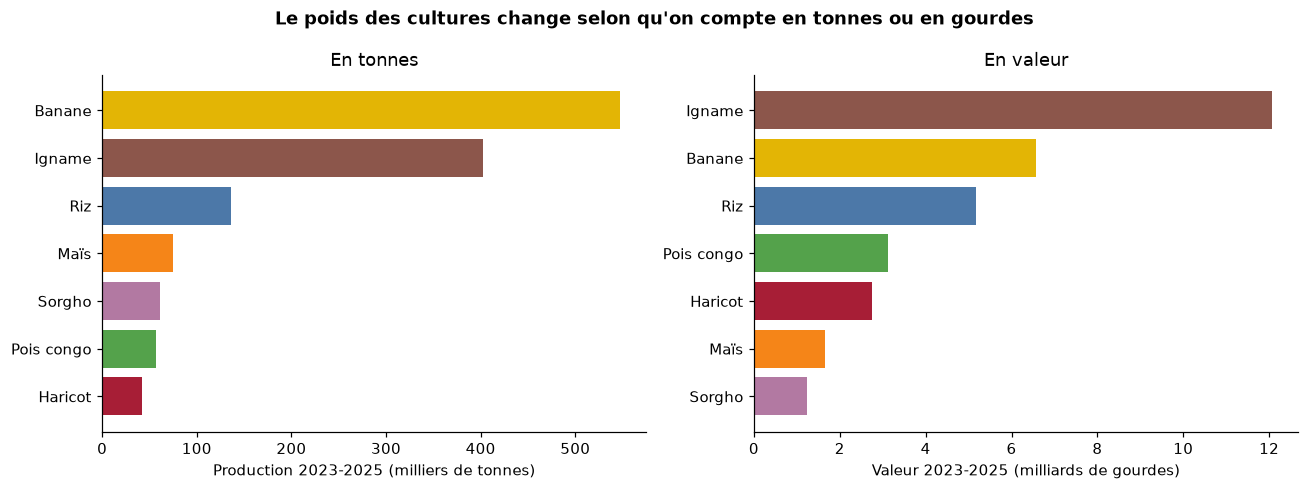

In [19]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(12, 4.5))

en_tonnes = poids.sort_values("production_t")
gauche.barh(en_tonnes.index, en_tonnes["production_t"] / 1000, color=[COULEURS[c] for c in en_tonnes.index])
gauche.set_title("En tonnes")
gauche.set_xlabel("Production 2023-2025 (milliers de tonnes)")

en_valeur = poids.sort_values("valeur_htg")
droite.barh(en_valeur.index, en_valeur["valeur_htg"] / 1e9, color=[COULEURS[c] for c in en_valeur.index])
droite.set_title("En valeur")
droite.set_xlabel("Valeur 2023-2025 (milliards de gourdes)")

fig.suptitle("Le poids des cultures change selon qu'on compte en tonnes ou en gourdes", fontweight="bold")
fig.tight_layout()
plt.show()

Le classement se lit mieux en reliant les deux rangs : une ligne qui monte est une culture qui pèse plus en gourdes qu'en tonnes.

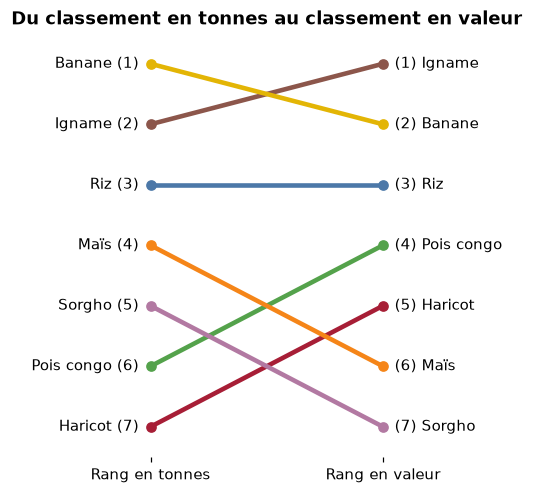

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
for culture, ligne in poids.iterrows():
    ax.plot([0, 1], [ligne["rang_tonnes"], ligne["rang_valeur"]], marker="o", linewidth=3, color=COULEURS[culture])
    ax.text(-0.05, ligne["rang_tonnes"], f"{culture} ({ligne['rang_tonnes']:.0f})", ha="right", va="center")
    ax.text(1.05, ligne["rang_valeur"], f"({ligne['rang_valeur']:.0f}) {culture}", ha="left", va="center")
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(7.5, 0.5)
ax.set_xticks([0, 1], ["Rang en tonnes", "Rang en valeur"])
ax.set_yticks([])
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Du classement en tonnes au classement en valeur", fontweight="bold")
plt.show()

**Ce qu'on en conclut :** en tonnes, la **banane** domine (547 615 t, 41 % du total), devant l'igname et le riz. En valeur, le classement change : l'**igname** passe en tête avec 12,1 milliards de gourdes (37 % de la valeur), presque le double de la banane, vendue seulement 12 HTG le kilo. Les légumineuses montent aussi : le **haricot**, dernier en tonnes, est 5e en valeur grâce à son prix de 65 HTG le kilo, et le pois congo passe de la 6e à la 4e place. Le maïs et le sorgho, bon marché, reculent en fin de classement. Compter en tonnes surestime donc les cultures lourdes et bon marché.

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

Le rendement d'un groupe de lignes se calcule en divisant **la somme des tonnes par la somme des hectares**, et non en faisant la moyenne des rendements : une petite parcelle ne doit pas peser autant qu'une grande.

In [21]:
somme = complet.groupby(["culture", "departement"])[["production_t", "surface_ha", "production_attendue_t"]].sum()
rendements = (somme["production_t"] / somme["surface_ha"]).unstack().round(2)
indice = (somme["production_t"] / somme["production_attendue_t"]).unstack()
rendements

departement,Artibonite,Centre,Grand'Anse,Nippes,Nord,Nord-Est,Nord-Ouest,Ouest,Sud,Sud-Est
culture,,,,,,,,,,
Banane,7.10,6.64,8.66,7.21,9.05,6.23,6.55,6.89,8.01,7.04
Haricot,0.64,0.78,0.69,0.71,0.70,0.61,0.60,0.63,0.88,0.66
Igname,5.79,5.53,8.24,5.30,5.74,5.32,5.44,5.74,6.56,5.76
Maïs,0.96,1.20,1.11,1.05,1.08,0.91,0.99,1.06,1.15,0.92
Pois congo,0.77,0.82,0.73,0.76,0.74,0.63,1.01,0.80,0.80,0.76
Riz,3.80,NaN,NaN,NaN,2.43,2.12,NaN,2.38,2.68,NaN
Sorgho,0.79,1.08,0.91,0.85,0.90,0.77,0.82,0.83,0.80,0.88


Chaque culture a son échelle (7 t/ha pour la banane, 0,7 pour le haricot). Pour tout voir sur un seul graphique, on colore chaque case par son **indice** : le rendement divisé par le rendement de référence de la culture. 1,20 veut dire 20 % au-dessus de la référence.

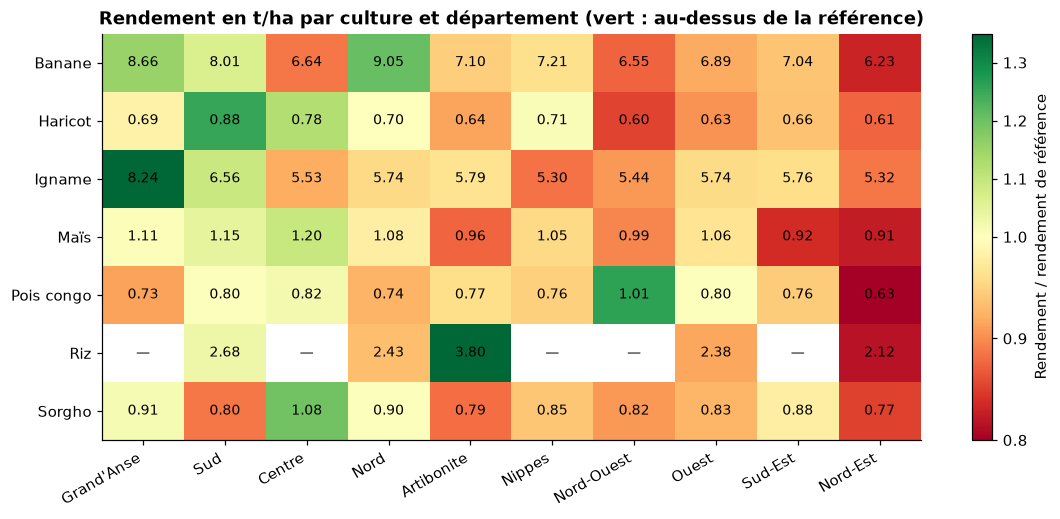

In [22]:
from matplotlib.colors import TwoSlopeNorm

ordre = indice.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 4.8))
image = ax.imshow(indice[ordre], cmap="RdYlGn", norm=TwoSlopeNorm(vmin=0.8, vcenter=1, vmax=1.35), aspect="auto")
for i, culture in enumerate(indice.index):
    for j, departement in enumerate(ordre):
        valeur = rendements.loc[culture, departement]
        texte = "—" if pd.isna(valeur) else f"{valeur:.2f}"
        ax.text(j, i, texte, ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(ordre)), ordre, rotation=30, ha="right")
ax.set_yticks(range(len(indice.index)), indice.index)
fig.colorbar(image, label="Rendement / rendement de référence")
ax.set_title("Rendement en t/ha par culture et département (vert : au-dessus de la référence)", fontweight="bold")
plt.show()

In [23]:
meilleurs = pd.DataFrame({
    "meilleur_departement": rendements.idxmax(axis=1),
    "rendement_t_ha": rendements.max(axis=1),
    "reference_t_ha": cultures.set_index("culture")["rendement_moyen_t_ha"],
})
meilleurs["ecart_reference_%"] = (100 * (meilleurs["rendement_t_ha"] / meilleurs["reference_t_ha"] - 1)).round(0)
meilleurs.sort_values("ecart_reference_%", ascending=False)

,meilleur_departement,rendement_t_ha,reference_t_ha,ecart_reference_%
culture,,,,
Riz,Artibonite,3.80,2.6,46.0
Igname,Grand'Anse,8.24,6.0,37.0
Haricot,Sud,0.88,0.7,26.0
Pois congo,Nord-Ouest,1.01,0.8,26.0
Banane,Nord,9.05,7.5,21.0
Sorgho,Centre,1.08,0.9,20.0
Maïs,Centre,1.20,1.1,9.0


**Ce qu'on en conclut :** il n'y a pas un département champion pour tout. La **Grand'Anse** a les meilleurs rendements en igname (8,24 t/ha, 37 % au-dessus de la référence) et rend très bien en banane. Le **Nord** a la meilleure banane, le **Centre** le meilleur maïs et le meilleur sorgho, le **Sud** le meilleur haricot, le **Nord-Ouest** le meilleur pois congo et l'**Artibonite** le meilleur riz (3,80 t/ha, 46 % au-dessus de la référence de 2,6). À l'inverse, l'Ouest, le Sud-Est et le Nord-Est restent sous la référence pour presque toutes les cultures.

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

Pour chaque culture, un nuage de points : une saison dans un département = un point. La droite est l'ajustement linéaire (`np.polyfit`), et `r` le coefficient de corrélation : proche de 1, plus il pleut, plus on récolte ; proche de 0, aucun lien.

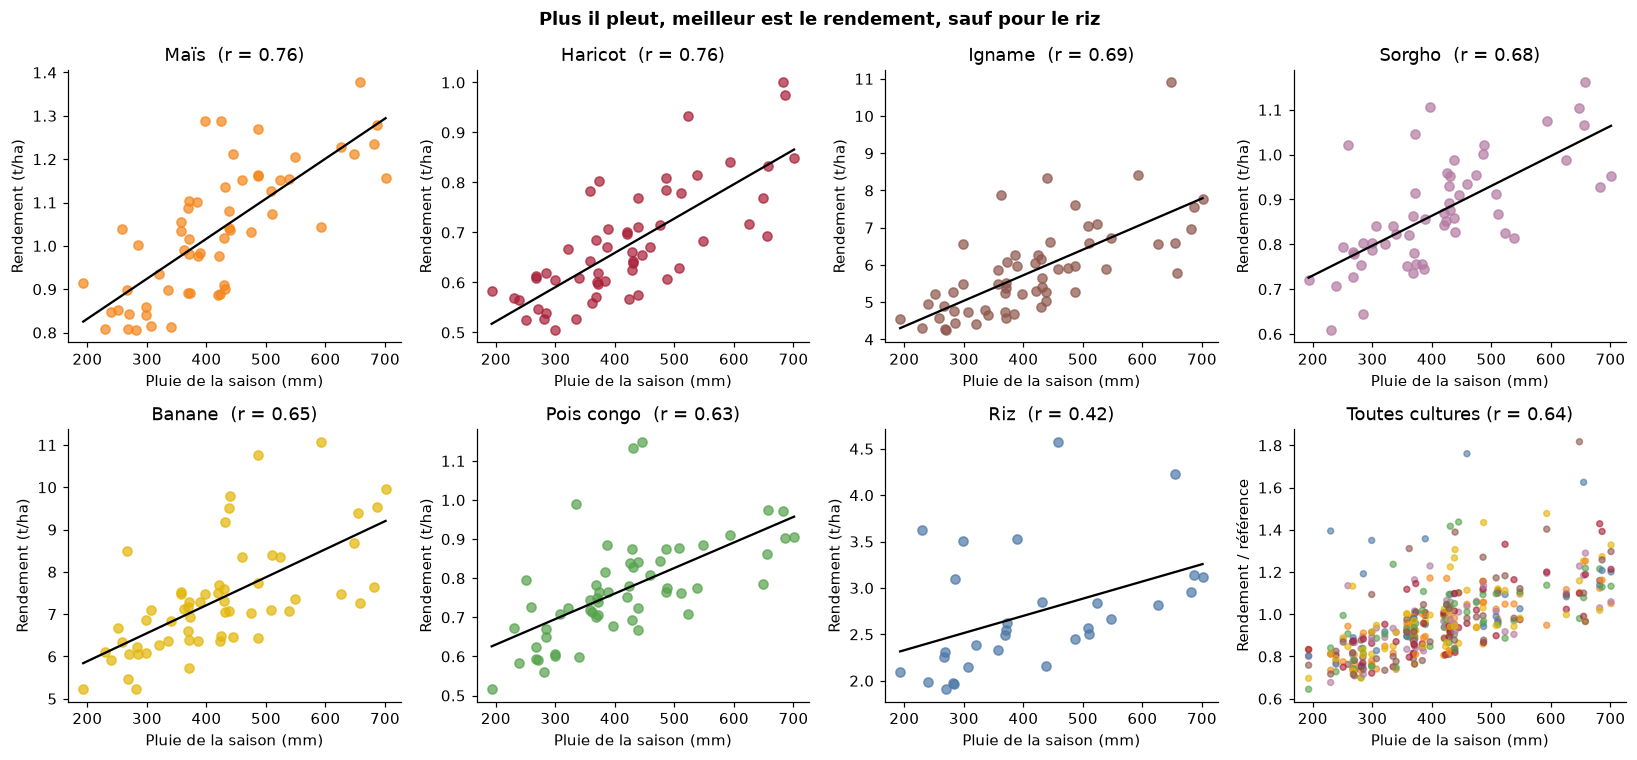

In [24]:
import numpy as np

ordre_cultures = ["Maïs", "Haricot", "Igname", "Sorgho", "Banane", "Pois congo", "Riz"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
correlations = {}

for ax, culture in zip(axes.flat, ordre_cultures):
    lignes = complet[complet["culture"] == culture]
    r = lignes["pluie_mm"].corr(lignes["rendement_t_ha"])
    correlations[culture] = r
    ax.scatter(lignes["pluie_mm"], lignes["rendement_t_ha"], color=COULEURS[culture], alpha=0.7)
    pente, origine = np.polyfit(lignes["pluie_mm"], lignes["rendement_t_ha"], 1)
    x = np.array([lignes["pluie_mm"].min(), lignes["pluie_mm"].max()])
    ax.plot(x, pente * x + origine, color="black", linewidth=1.5)
    ax.set_title(f"{culture}  (r = {r:.2f})")
    ax.set_xlabel("Pluie de la saison (mm)")
    ax.set_ylabel("Rendement (t/ha)")

# Dernière case : toutes les cultures ensemble, grâce à l'indice de rendement.
ax = axes.flat[7]
indice_ligne = complet["production_t"] / complet["production_attendue_t"]
ax.scatter(complet["pluie_mm"], indice_ligne, c=complet["culture"].map(COULEURS), alpha=0.6, s=15)
r_tout = complet["pluie_mm"].corr(indice_ligne)
ax.set_title(f"Toutes cultures (r = {r_tout:.2f})")
ax.set_xlabel("Pluie de la saison (mm)")
ax.set_ylabel("Rendement / référence")

fig.suptitle("Plus il pleut, meilleur est le rendement, sauf pour le riz", fontweight="bold")
fig.tight_layout()
plt.show()

In [25]:
lien = pd.DataFrame({"r": pd.Series(correlations)})
lien["r2_%"] = (100 * lien["r"] ** 2).round(0)
lien.sort_values("r", ascending=False).round(2)

,r,r2_%
Haricot,0.76,58.0
Maïs,0.76,57.0
Igname,0.69,48.0
Sorgho,0.68,47.0
Banane,0.65,42.0
Pois congo,0.63,39.0
Riz,0.42,18.0


`r²` est la part des écarts de rendement que la pluie « explique » à elle seule : avec r = 0,76, la pluie explique environ 58 % des variations de rendement du haricot.

In [26]:
saisons = complet.groupby(["annee", "saison"]).agg(
    pluie_moyenne_mm=("pluie_mm", "mean"),
    production_t=("production_t", "sum"),
    attendue_t=("production_attendue_t", "sum"),
)
saisons["indice_rendement"] = saisons["production_t"] / saisons["attendue_t"]
saisons.drop(columns="attendue_t").round({"pluie_moyenne_mm": 0, "indice_rendement": 2})

pluie_moyenne_mm  production_t  indice_rendement
annee saison                                                     
2023  Automne               351.0        240250              0.89
      Printemps             477.0        229679              1.03
2024  Automne               349.0        164958              0.92
      Printemps             532.0        247220              1.09
2025  Automne               357.0        207814              0.92
      Printemps             435.0        231835              1.06

**Ce qu'on en conclut :** oui, la pluie explique une grande partie des rendements. Le lien est fort pour le **maïs** et le **haricot** (r = 0,76 : la pluie explique environ 58 % de leurs variations), puis pour l'igname, le sorgho, la banane et le pois congo (r entre 0,63 et 0,69). Le **riz** dépend beaucoup moins de la pluie (r = 0,42) : c'est cohérent avec une culture souvent irriguée, comme dans la vallée de l'Artibonite. Les **automnes**, plus secs (environ 350 mm contre 435 à 532 mm au printemps), rendent 8 à 11 % sous la référence, quand les printemps sont 3 à 9 % au-dessus. En revanche, la plus petite récolte, l'automne 2024, n'a pas un rendement plus mauvais que les autres automnes : elle vient de surfaces plus faibles, pas de la pluie. Attention : une corrélation ne prouve pas la cause, car les départements les plus pluvieux diffèrent aussi par leurs sols.

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

**Ce qu'on en conclut :**

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

**Ce qu'on en conclut :**

## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.